# Notebook 4: from experiment to a working tool (the prototype)

So far everything lived in notebooks. A tool that developers can actually use needs three more things:

```
 a developer's CI run FAILS
        |
        v
 GitHub Action  (triage_action.py)      asks GitHub: which jobs failed? how busy/failing has the project been?
        |  numbers
        v
 Triage API     (api.py)                the saved model turns the numbers into P(flaky) and a decision
        |  "rerun" or "human"
        v
 the Action writes a report (and, only if you switch it on, re-runs the failed jobs)
```

**What this notebook does**
1. Train the final model once and save it
2. Look at what it learned and at the decision rule
3. Start the API and talk to it
4. Check that the API gives the same answers as our experiments
5. Measure speed (latency) and reliability
6. Test the safety rules
7. Set up the real thing on GitHub (a checklist, because that part runs on GitHub, not here)

Same rules: read, guess, run, check.

## Step 0: Setup

In [1]:
import json, os, subprocess, sys, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests
pd.set_option("display.width", 140)
for pkg in ("fastapi", "uvicorn", "joblib"):
    try: __import__(pkg); print("ok:", pkg)
    except ImportError: print("MISSING:", pkg, " -> in the Anaconda Prompt run:  pip install fastapi uvicorn joblib httpx")

ok: fastapi
ok: uvicorn
ok: joblib


## Step 1: Train the final model

`train_final.py` does four things:
1. takes the same labelled jobs as the experiments,
2. gets honest scores for every job from models that never saw its project, and learns the **calibration** from those,
3. fits the **final model on all jobs**,
4. saves everything in the `model/` folder: the model, a **model card** (what it was trained on, how well it did, its limits) and the exact **library versions**.

*Why save the library versions?* A saved model only loads correctly in the same library versions. The GitHub runner reads that file and installs the same ones.

In [2]:
import train_final
card = train_final.main()

saved model to model/  (2370 jobs, 25 projects)
out-of-fold (unseen projects): {'pr_auc_real_failures': 0.379, 'roc_auc': 0.652, 'brier_raw': 0.178, 'brier_calibrated': 0.177, 'ece_calibrated': np.float64(0.024)}


In [3]:
print(json.dumps({k: card[k] for k in ("trained_at", "n_training_jobs", "n_projects", "share_flaky",
                                       "out_of_fold_scores_unseen_projects", "limitations")}, indent=2))

{
  "trained_at": "2026-11-17T09:43:48+00:00",
  "n_training_jobs": 2370,
  "n_projects": 25,
  "share_flaky": 0.7502,
  "out_of_fold_scores_unseen_projects": {
    "pr_auc_real_failures": 0.379,
    "roc_auc": 0.652,
    "brier_raw": 0.178,
    "brier_calibrated": 0.177,
    "ece_calibrated": 0.024
  },
  "limitations": [
    "trained only on jobs that someone re-ran (selection bias)",
    "25 projects, about two months of data",
    "labels are heuristic (passed on re-run = flaky)",
    "feature group chosen after looking at test results"
  ]
}


**Think 1.** The `out_of_fold_scores_unseen_projects` block is the *honest* estimate of how the model behaves on a new project. Compare it with what you saw in Notebook 2. Why is it wrong to quote the model's score on its own training jobs instead?

*My answer:*

## Step 2: What did the final model learn?

A logistic regression gives one weight per input. The inputs were put on the same scale first, so the weights are comparable: **positive pushes towards "flaky", negative towards "real"**.

In [4]:
import joblib
b = joblib.load("model/triage_model.joblib")
names = b["pipeline"].named_steps["pre"].get_feature_names_out()
w = b["pipeline"].named_steps["clf"].coef_[0]
coef = pd.Series(w, index=[n.split("__")[-1] for n in names]).sort_values()
coef.round(3).to_frame("weight")

,weight
repo_fail_rate_24h,-0.432
wf_fail_7d,-0.360
repo_n_1h,-0.347
n_failed_jobs_in_run,-0.295
wf_fail_rate_7d,-0.274
repo_fail_24h,0.078
repo_n_24h,0.093
repo_fail_1h,0.194
wf_n_7d,0.451


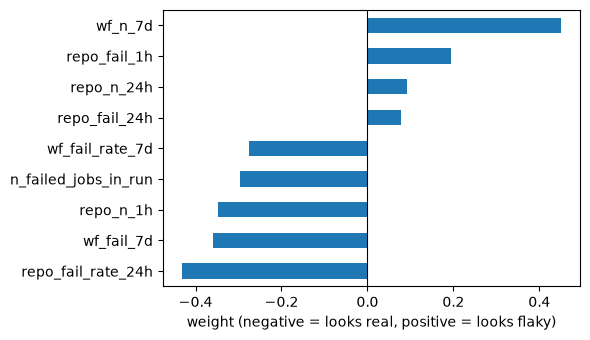

In [5]:
coef.plot.barh(figsize=(6, 3.5)); plt.axvline(0, c="k", lw=0.8)
plt.xlabel("weight (negative = looks real, positive = looks flaky)"); plt.tight_layout()
plt.savefig("results/final_model_weights.png", dpi=150)

**Think 2.** Which inputs push towards "real"? Does that agree with what you found in Notebook 1 (many jobs failing in one run, a project that has been failing a lot)? Remember that these inputs overlap (the counts and the rates tell similar stories), so don't read too much into any single weight.

*My answer:*

## Step 3: The decision rule, as a picture

The API doesn't only return a probability. It also decides, using the rule from Notebook 2: **re-run if P(flaky) is above a bar, and the bar depends on how long the job ran.**

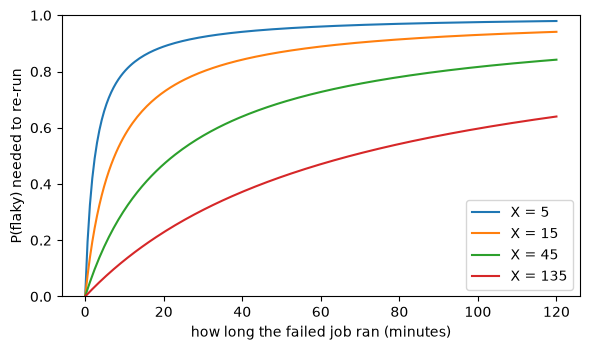

In [6]:
from triage_model import decision_threshold
d = np.linspace(0, 120, 200)
plt.figure(figsize=(6, 3.6))
for X in (5, 15, 45, 135):
    plt.plot(d, [decision_threshold(m, X, 1.0) for m in d], label=f"X = {X}")
plt.xlabel("how long the failed job ran (minutes)"); plt.ylabel("P(flaky) needed to re-run")
plt.legend(); plt.ylim(0, 1); plt.tight_layout(); plt.savefig("results/decision_bar.png", dpi=150)

**Think 3.** Read the picture: for a 10-minute job and X = 15, how sure must the model be before it re-runs? What happens to the bar when a human's time becomes more expensive (larger X)? Why does it rise with job length?

*My answer:*

## Step 4: Start the API and talk to it

We start the web service as a separate process (this is exactly how it will run on GitHub) and wait until it answers. The time this takes is the **cold start**.

In [7]:
PORT = 8010
URL = f"http://127.0.0.1:{PORT}"
server = subprocess.Popen([sys.executable, "-m", "uvicorn", "api:app", "--port", str(PORT)],
                          stdout=open("api_notebook.log", "w"), stderr=subprocess.STDOUT)
t0 = time.perf_counter()
for _ in range(100):
    try:
        if requests.get(f"{URL}/health", timeout=1).status_code == 200: break
    except Exception: time.sleep(0.2)
cold_start = time.perf_counter() - t0
print(f"API ready after {cold_start:.2f} s (cold start)")
print(requests.get(f"{URL}/health").json())

API ready after 3.68 s (cold start)
{'status': 'ok', 'model_load_seconds': 0.09730759996455163}


**One prediction by hand.** The API takes *counts* about the project's recent runs, how many jobs failed in this run, and how long the job ran. (It works out the rates itself, so training and serving can't disagree about how a rate is computed.)

In [8]:
example = {"repo_n_1h": 3, "repo_fail_1h": 1, "repo_n_24h": 40, "repo_fail_24h": 9,
           "wf_n_7d": 120, "wf_fail_7d": 25, "n_failed_jobs_in_run": 2, "job_duration_s": 420, "X": 15}
r = requests.post(f"{URL}/predict", json=example)
print(r.status_code); print(json.dumps(r.json(), indent=2))

200
{
  "p_flaky": 0.7589,
  "decision": "rerun",
  "threshold_p": 0.4828,
  "model_trained_at": "2026-11-17T09:43:48+00:00",
  "compute_ms": 89.226
}


Read the answer: `p_flaky` is the calibrated probability, `threshold_p` is the bar for *this* job length and X, `decision` is "rerun" if `p_flaky` is above the bar, and `compute_ms` is how long the model took.

**Change one number and run again.** Try `"job_duration_s": 7200` (a two-hour job), then `"X": 200`. Predict what happens to `threshold_p` before you run it.

In [9]:
for change in ({"job_duration_s": 7200}, {"X": 200}, {"n_failed_jobs_in_run": 12}):
    r = requests.post(f"{URL}/predict", json={**example, **change}).json()
    print(change, "->", {k: r[k] for k in ("p_flaky", "threshold_p", "decision")})

{'job_duration_s': 7200} -> {'p_flaky': 0.7589, 'threshold_p': 0.9412, 'decision': 'human'}
{'X': 200} -> {'p_flaky': 0.7589, 'threshold_p': 0.0654, 'decision': 'rerun'}
{'n_failed_jobs_in_run': 12} -> {'p_flaky': 0.698, 'threshold_p': 0.4828, 'decision': 'rerun'}


**A bad request must be refused, not guessed at.** Here a project claims more failures than runs, which is impossible.

In [10]:
bad = requests.post(f"{URL}/predict", json={**example, "repo_fail_24h": 99})
print(bad.status_code); print(bad.json()["detail"][0]["msg"])

422
Value error, repo_fail_24h cannot be larger than repo_n_24h


**Think 4.** Why is it better for the service to answer "422, your input is impossible" than to compute some number anyway? What could go wrong in a deployed system if it silently accepted nonsense?

*My answer:*

## Step 5: Does the API give the same answers as our experiments?

If the service and the model in Python disagreed even slightly, every result we reported would be about something that isn't deployed. We check 150 real jobs.

In [11]:
from baselines import load_main
from triage_model import FEATURES
data = load_main()
ok = ((data.repo_fail_1h <= data.repo_n_1h) & (data.repo_fail_24h <= data.repo_n_24h) & (data.wf_fail_7d <= data.wf_n_7d))
print("rows with impossible counts:", int((~ok).sum()), "of", len(data))
sample = data[ok].sample(150, random_state=1)
keys = ["repo_n_1h", "repo_fail_1h", "repo_n_24h", "repo_fail_24h", "wf_n_7d", "wf_fail_7d", "n_failed_jobs_in_run"]
diffs = []
for _, r in sample.iterrows():
    payload = {k: int(r[k]) for k in keys}; payload["job_duration_s"] = float(np.nan_to_num(r["job_duration_s"]))
    api_p = requests.post(f"{URL}/predict", json=payload).json()["p_flaky"]
    x = pd.DataFrame([r[FEATURES]], columns=FEATURES).astype(float)
    off = float(b["calibrator"].predict(b["pipeline"].predict_proba(x)[:, 1])[0])
    diffs.append(abs(api_p - off))
print(f"largest difference between API and offline model: {max(diffs):.6f}  (the API rounds to 4 decimals)")

rows with impossible counts: 0 of 2370
largest difference between API and offline model: 0.000049  (the API rounds to 4 decimals)


## Step 6: How fast is it? (latency)

Latency = how long one request takes from asking to answer. We send 500 requests one after another, then 1000 with 8 at once. The first 20 of each are a warm-up and are not counted.

**Important limit.** This measures the model service on *this* computer. On GitHub the runner is different, and the biggest part of the real time is calling GitHub's own API to collect the inputs. The Action prints its own timings, and Step 8 shows how to read them.

In [12]:
from bench_api import payloads
def bench(n, threads):
    from concurrent.futures import ThreadPoolExecutor
    reqs = payloads(n)
    def one(p):
        t0 = time.perf_counter()
        try:
            ok = requests.post(f"{URL}/predict", json=p, timeout=10).status_code == 200
        except Exception: ok = False
        return (time.perf_counter() - t0) * 1000, ok
    for p in reqs[:20]: one(p)
    t0 = time.perf_counter()
    with ThreadPoolExecutor(threads) as ex: res = list(ex.map(one, reqs))
    wall = time.perf_counter() - t0
    lat = np.array([a for a, ok in res if ok]); err = sum(1 for _, ok in res if not ok)
    return lat, err, n / wall
rows, lats = [], {}
for n, th in ((500, 1), (1000, 8)):
    lat, err, thr = bench(n, th); lats[th] = lat
    rows.append({"requests": n, "threads": th, "errors": err, "p50_ms": np.percentile(lat, 50),
                 "p95_ms": np.percentile(lat, 95), "p99_ms": np.percentile(lat, 99), "req_per_s": thr})
lat_table = pd.DataFrame(rows).round(1)
lat_table.to_csv("results/api_latency.csv", index=False)
lat_table

,requests,threads,errors,p50_ms,p95_ms,p99_ms,req_per_s
0,500,1,0,31.3,35.7,37.5,34.9
1,1000,8,0,67.1,89.2,104.3,118.0


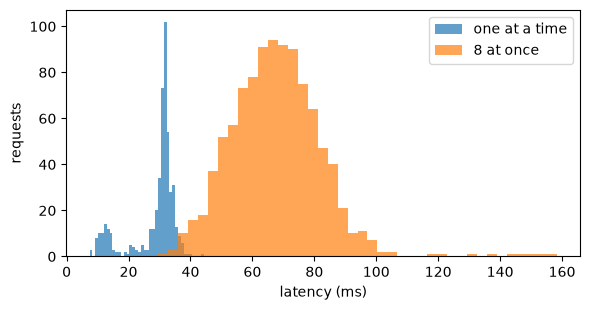

In [13]:
plt.figure(figsize=(6, 3.2))
plt.hist(lats[1], bins=40, alpha=0.7, label="one at a time"); plt.hist(lats[8], bins=40, alpha=0.7, label="8 at once")
plt.xlabel("latency (ms)"); plt.ylabel("requests"); plt.legend(); plt.tight_layout()
plt.savefig("results/api_latency.png", dpi=150)

**Think 5.** Why does latency go up when 8 requests arrive at once, even though the throughput barely changes? Is a typical CI failure going to send 8 requests at once? What does that say about whether speed is a problem for this tool?

*My answer:*

## Step 7: Reliability and safety

A triage tool must never make CI *worse*. `test_prototype.py` checks the promises we make:
- the features computed for GitHub **match** the ones used in training (parity),
- the API **matches** the offline model,
- impossible input is **rejected**,
- the decision rule behaves as described,
- the Action is **safe**: dry run by default, never re-runs a re-run, leaves many-job failures to a human, and falls back to "human" if the API is down.

Run all of them:

In [14]:
res = subprocess.run([sys.executable, "test_prototype.py"], capture_output=True, text=True)
print(res.stdout[-2500:]); print(res.stderr[-800:])

test_feature_parity
  checked 240 jobs: every feature identical
test_api_matches_offline
  150 jobs: largest difference between API and offline = 0.000049
test_validation
  bad inputs are rejected with 422
test_decision_rule
  threshold grows with job length, shrinks as human steps get costlier
test_action_safety
  dry run, no loops, many-jobs guard, PR comment, API-down fallback: all behave

ALL TESTS PASSED




**Now break the service on purpose.** We stop the API and then ask for a decision the way the Action does. The answer must be "human", and nothing must crash.

In [15]:
server.terminate(); server.wait(timeout=10)
import triage_action as ta
ans, ms, err = ta.predict(URL, example, retries=1, timeout=1)
print("answer:", ans); print("error :", err)
print("decision used by the Action:", "human (fallback)" if ans is None else ans["decision"])

answer: None
error : ConnectTimeout: HTTPConnectionPool(host='127.0.0.1', port=8010): Max retries exceeded with url: /predict (Caused by ConnectTimeoutError(<HTTPConnection(host='127.0.0.1', port=8010) at 0x22c7c83fe90>, 'Connection to 127.0.0.1 timed out. (connect timeout=1)'))
decision used by the Action: human (fallback)


**Think 6.** The Action answers "human" when the API fails, instead of "rerun". Which mistake is worse for a team: an automatic re-run that wasn't needed, or no automation for a while? Why is a *quiet* failure more dangerous than a loud one, and how does the Action avoid being quiet? (Look at `::warning::` in `triage_action.py`.)

*My answer:*

## Step 8: Put it on GitHub

This part runs on GitHub, so it is a checklist. The files are in the bundle I sent.

**1. Make a small demo repository** on your GitHub account (public is fine), e.g. `ci-triage-demo`.

**2. Add these files** (same folder layout as your project):
```
.github/workflows/demo-flaky.yml      a pretend project whose tests sometimes fail for no reason
.github/workflows/ci-triage.yml       the triage, runs when the demo fails
api.py  triage_model.py  triage_features.py  triage_action.py
requirements-serve.txt
model/triage_model.joblib  model/model_card.json  model/requirements.lock.txt
```
(`model/` is created by Step 1 above.) Push them to the **default branch**. The `workflow_run` trigger only works from the default branch.

**3. Run the demo.** Actions tab, "Demo flaky CI", "Run workflow", mode `flaky`, a few times. Some runs fail on the first attempt. Each failure starts "CI failure triage" automatically.

**4. Look at the result.** Open a triage run, then its **Summary** page: you get a table with P(flaky) and the decision for every failed job. In the log, the line starting `TRIAGE_METRICS` has the timings.

**5. Try the real failure.** Run the demo with mode `broken`. The triage should say "human".

**6. Only when you trust it:** Settings, Secrets and variables, Actions, Variables: add `AUTO_RERUN` = `true`. Until then it only reports (dry run).

**7. Measure reliability** after about 20 demo runs. In the Anaconda Prompt: `python triage_report.py your-name/ci-triage-demo` (needs a token as in the collector).

In [16]:
print(open(".github/workflows/ci-triage.yml").read())

# Runs when the watched workflow finishes. Only acts if it FAILED.
# NOTE: for a `workflow_run` trigger, this file must be on the repository's default branch.
name: CI failure triage

on:
  workflow_run:
    workflows: ["Demo flaky CI"]      # <-- put the name(s) of the workflow(s) to watch here
    types: [completed]

permissions:
  contents: read
  actions: write          # needed to re-run failed jobs
  pull-requests: write    # needed to comment on a pull request

jobs:
  triage:
    if: ${{ github.event.workflow_run.conclusion == 'failure' }}
    runs-on: ubuntu-latest
    timeout-minutes: 10
    steps:
      - uses: actions/checkout@v4

      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"

      - name: Install (same library versions as training)
        run: pip install -r model/requirements.lock.txt -r requirements-serve.txt

      - name: Start the triage API on this runner
        run: |
          nohup python -m uvicorn api:app --host 127.0.0.

## Step 9: Clean up and conclusions

In [17]:
try:
    server.terminate()
except Exception: pass
print("API stopped")

API stopped


**Your conclusions (6 to 8 sentences).** What did you build? How do you know the deployed model is the same as the one you evaluated? How fast is it, and what does that measurement not include? What happens when something fails? What would you want to know before letting it re-run jobs automatically in a real team? An examiner will ask about each of these.

*My conclusions:*